# Notebook 06: Explainability with SHAP on a Random Forest regression model

This notebook builds on previous work to explore explainability in nonlinear models
using SHAP values and a Random Forest regressor.

In [122]:
# ----------------------------------
# 1. Setup: Load and prepare data
# ----------------------------------
import pandas
from datetime import datetime

In [124]:
my_path = "/Users/spb24/Downloads/coherent-11-07-2022/csv/"
patients = pandas.read_csv(my_path + "patients.csv")

In [126]:
patients['BIRTHDATE'] = pandas.to_datetime(patients['BIRTHDATE'], errors='coerce')
patients['age'] = (datetime.today() - patients['BIRTHDATE']).dt.days // 365
model_df = patients[['age', 'GENDER', 'HEALTHCARE_EXPENSES']].dropna()
model_df['male'] = model_df['GENDER'].map({'M': 1, 'F': 0})

In [128]:
# ----------------------------------
# 2. Train Random Forest model
# ----------------------------------
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [138]:
X = model_df[['age', 'male']]
y = model_df['HEALTHCARE_EXPENSES']

In [161]:
X.head(5)

,age,male
0,68,1
1,49,1
2,80,1
3,77,0
4,32,0


In [132]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [134]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [136]:
print("MSE:", mean_squared_error(y_test, rf_model.predict(X_test)))
print("R^2:", r2_score(y_test, rf_model.predict(X_test)))

MSE: 268874543667.38818
R^2: 0.20335955051659793


### Interpreting Random Forest MSE and R-squared

- **MSE (Mean Squared Error)** tells us, on average, how far off our model's predictions are from the real values.
- Lower is better — but "how low is good?" depends on the scale of the outcome variable.

👉 Here, we mainly use MSE to **compare** models, not to judge in isolation.

- R-squared tells us roughly the amount of variance in Y that is explained by our X variables.
- Higher is better, with an R-squared = 1.0 meaning Y and X are the same data, perhaps by different names.
- In a bivariate regression (Y=X), R-squared is the Pearson's correlation for X against Y, squared.    

👉 R-squared is useful in comparing models, such as when deciding whether to include or exclude an explanatory (X) variable. 


## Quick Check: LIME on Random Forest?

Before we jump into SHAP, let's take one more quick look at how LIME behaves when we apply it to a **Random Forest** model instead of a simple regression.

- Remember: **LIME builds a local, simple model** around one prediction.
- Random Forest is **messy and nonlinear** — lots of little decision rules.
- So, it's *harder* for LIME to make a good simple explanation here.

Let's see what happens!


In [141]:
# ----------------------------------
# 3. Revisit: LIME  
# ----------------------------------
import lime
import lime.lime_tabular
import numpy as np

In [143]:
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X_train.columns,
    mode='regression'
)

In [145]:
lime_exp = lime_explainer.explain_instance(
    data_row=X_test.iloc[0],
    predict_fn=rf_model.predict
)

/opt/anaconda3/lib/python3.12/site-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/opt/anaconda3/lib/python3.12/site-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/opt/anaconda3/lib/python3.12/site-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by positio

In [149]:
# lime_exp.show_in_notebook(show_table=True)
# lime_exp.as_pyplot_figure()
lime_exp.as_list()

[('89.00 < age <= 102.00', 178981.81649804887),
 ('0.00 < male <= 1.00', 20360.185634848098)]

## Moving Beyond LIME: Why We Need SHAP

LIME is great for simple explanations, but when models get complex (like Random Forests), we need a tool that is:

- Designed for **nonlinear models**
- Mathematically **fair** to all features
- **Locally accurate** *and* **globally consistent**

That's where **SHAP** comes in. SHAP helps explain **how much each feature pushes the prediction up or down** — for every single prediction, and across the whole model.

Let's dive in!


In [152]:
# ----------------------------------
# 4. SHAP explanation for Random Forest
# ----------------------------------
import shap

In [154]:
# Initialize SHAP explainer for tree models
shap_explainer = shap.Explainer(rf_model, X_train)
shap_values = shap_explainer(X_test)

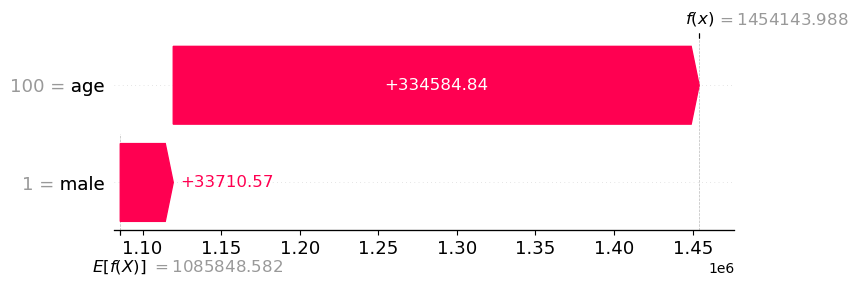

In [155]:
# Visualize first prediction explanation
shap.plots.waterfall(shap_values[0])

### How to Read This SHAP Waterfall Plot

- The **base value** is the average prediction for everyone.
- Features like `age` and `male` **push the prediction up or down** from that baseline.
- Red bars push the prediction higher; blue bars push it lower.

👉 You can "walk" along the plot and **see how the model decided** on the final prediction for one patient.


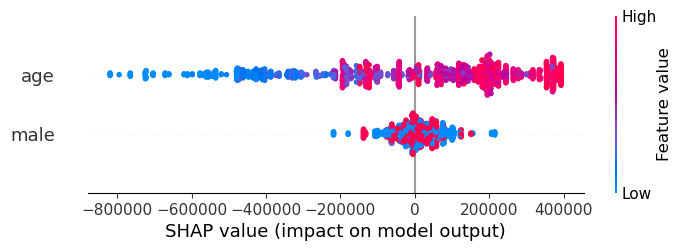

In [159]:
# Summary plot for feature importance
shap.plots.beeswarm(shap_values)

### What the SHAP Beeswarm Plot Tells Us

- Each dot is a patient.
- The color shows the feature value (e.g., young = blue, old = red).
- Position on X-axis = how much that feature pushed the prediction.

👉 Big spread? Feature has a strong influence.  
👉 Tight clump? Feature doesn't matter much for most predictions.


## Interpretation Tip: LIME vs. Global Models
 ------------------------------------------------
 While the OLS and scikit-learn linear models report a negative coefficient for `male`,
 LIME shows a **positive contribution** to the prediction for the individual patient.
 This is not a contradiction—it’s an important insight about how local and global explanations differ.

 - OLS says: `Across all patients, males tend to have ~$4K LOWER expenses.`
 - LIME says: `For *this* 100-year-old male, maleness ADDS ~$3K to the prediction.`

 This is because LIME is fitting a linear surrogate model in the **local neighborhood** of this patient.
 The influence of a feature can vary depending on where in the feature space you're standing.

 ➡️ Key takeaway: LIME helps us understand how the model behaves **here**, not **everywhere**.
                 SHAP shows the model's influence **across the range** of explanatory variables, or features.

## Reflect:
- How does SHAP's explanation differ from LIME's?
- Which visualization (waterfall or beeswarm) helped you understand the model better?
- How does explainability change when the model becomes nonlinear or ensemble-based?
- What challenges might arise when trying to communicate SHAP explanations to clinicians?
- What are the strengths and weaknesses of using local (e.g., LIME) vs. global (e.g., SHAP summary) explanations?
